In [1]:
!pip install pandas matplotlib scikit-learn

Accuracy: 0.7777777777777778
F1 Score: 0.8461538461538461

 Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.60      0.60         5
           1       0.85      0.85      0.85        13

    accuracy                           0.78        18
   macro avg       0.72      0.72      0.72        18
weighted avg       0.78      0.78      0.78        18


 Features Importance:
Weather          0.728665
BusyRunways      0.212617
CrewAvailable    0.058718
dtype: float64


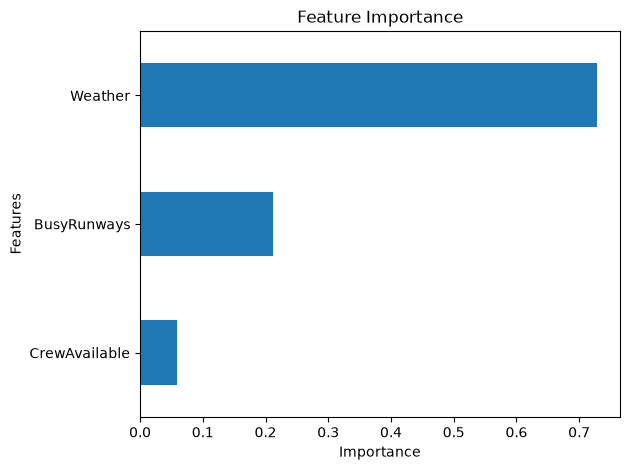

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,f1_score, classification_report


#load the data
df = pd.read_csv('/tmp/airline-weather.csv')

#select input and output columns
features = df[['Weather','CrewAvailable','BusyRunways']].copy()
target = df['DelayedYN'].astype(str).str.strip().str.lower()
target = target.map({'no': 0, 'yes': 1})


#convert text features into numbers
for column in features.columns:
  features[column] = features[column].astype('category').cat.codes

features_train, features_test, target_train, target_test = train_test_split(
    features, target, test_size=0.2, random_state=42
)

#train the model 
model = RandomForestClassifier(random_state=42)
model.fit(features_train, target_train)

#predict the test data
predictions = model.predict(features_test)

#display model performance
print("Accuracy:", accuracy_score(target_test, predictions))
print("F1 Score:", f1_score(target_test, predictions))
print("\n Classification Report:")
print(classification_report(target_test,predictions))

#display feature importance
importance = pd.Series(
    model.feature_importances_,
    index=features.columns
)

print("\n Features Importance:")
print(importance.sort_values(ascending=False))

#Plot features importance
importance.sort_values().plot(kind='barh')
plt.title('Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()